# 06 — Random Forest Ensemble Classification

## Loan Default Risk Classification (Binary Task)


## 1. Imports and Configuration


In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_featured.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_featured.xlsx')

print(f'Loading data from: {DATA_PATH}')

Loading data from: ..\..\data\processed\loan_featured.xlsx


## 2. Ingestion & Preprocessing Setup


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Featured')

# Binary target
y = (df['Loan_Default'] == 'Yes').astype(int)

# Exclude leakage
drop_cols = ['Applicant_ID', 'Application_Date', 'Risk_Category', 'Loan_Default']
X = df.drop(columns=drop_cols)

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_cols = [
    'Age', 'Years_Employed', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months',
    'Interest_Rate_Pct', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
    'Debt_to_Income', 'Loan_to_Income', 'Loan_to_Value', 'Savings_to_Income',
    'Log_Annual_Income', 'Log_Loan_Amount', 'Log_Savings_Balance'
]

nominal_cols = [
    'Marital_Status', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
    'Loan_Purpose', 'Region', 'Application_Channel'
]

binary_cols = [
    'Gender', 'Salary_Account_With_Bank', 'Vehicle_Owned', 'Has_Co_Applicant',
    'Previous_Default', 'Mobile_Banking_User', 'Ever_Delinquent', 'Is_Home_Loan'
]

ordinal_cols = ['Education_Level']
education_hierarchy = [['High School', 'Diploma', 'Bachelor', 'Master', 'PhD']]

# Preprocessor for tree ensembles: Imputation and categorical encoding (scale-invariant)
preprocessor = ColumnTransformer(transformers=[
    ('num', SimpleImputer(strategy='median'), numeric_cols),
    ('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))]), nominal_cols),
    ('ord', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ord', OrdinalEncoder(categories=education_hierarchy))]), ordinal_cols),
    ('bin', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OrdinalEncoder())]), binary_cols)
], remainder='drop')


## 3. The Bias-Variance Decomposition & Model Taxonomy


In [3]:
# Bias-Variance Taxonomy Map
bv_taxonomy = [
    {'Model_Configuration': 'Depth-2 Decision Tree', 'Bias_Level': 'High Bias', 'Variance_Level': 'Low Variance', 'Fitting_Diagnosis': 'Severe Underfitting', 'Rationale': 'Only 4 leaves; misses non-linear interactions'},
    {'Model_Configuration': 'Depth-15 Decision Tree', 'Bias_Level': 'Low Bias', 'Variance_Level': 'Very High Variance', 'Fitting_Diagnosis': 'Severe Overfitting', 'Rationale': 'Splits on noise; high leaf purity on tiny samples'},
    {'Model_Configuration': 'KNN (k=1)', 'Bias_Level': 'Very Low Bias', 'Variance_Level': 'Extreme Variance', 'Fitting_Diagnosis': 'Severe Overfitting', 'Rationale': 'Memorizes training labels; Voronoi boundaries around outliers'},
    {'Model_Configuration': 'KNN (k=75)', 'Bias_Level': 'High Bias', 'Variance_Level': 'Low Variance', 'Fitting_Diagnosis': 'Underfitting', 'Rationale': 'Oversmooths local neighborhoods into global average'},
    {'Model_Configuration': 'Linear SVM (C=1.0)', 'Bias_Level': 'Moderate Bias', 'Variance_Level': 'Low Variance', 'Fitting_Diagnosis': 'Well-Regularized Balance', 'Rationale': 'Maximizes margin width; stable linear hyperplane'},
    {'Model_Configuration': 'RBF SVM (very large gamma)', 'Bias_Level': 'Low Bias', 'Variance_Level': 'Extreme Variance', 'Fitting_Diagnosis': 'Severe Overfitting', 'Rationale': 'Gaussian bells are so narrow that each point becomes an isolated island'},
    {'Model_Configuration': 'Random Forest (100 trees)', 'Bias_Level': 'Low Bias', 'Variance_Level': 'Low-to-Moderate Variance', 'Fitting_Diagnosis': 'Optimal Production Fit', 'Rationale': 'Bagging + feature subsampling reduces variance by decorrelating trees'}
]

df_bv_map = pd.DataFrame(bv_taxonomy)
df_bv_map.to_csv('../../outputs/tables/bias_variance_model_taxonomy.csv', index=False)
print('=== The Bias-Variance Model Taxonomy Map ===')
display(df_bv_map)

=== The Bias-Variance Model Taxonomy Map ===


,Model_Configuration,Bias_Level,Variance_Level,Fitting_Diagnosis,Rationale
0,Depth-2 Decision Tree,High Bias,Low Variance,Severe Underfitting,Only 4 leaves; misses non-linear interactions
1,Depth-15 Decision Tree,Low Bias,Very High Variance,Severe Overfitting,Splits on noise; high leaf purity on tiny samples
2,KNN (k=1),Very Low Bias,Extreme Variance,Severe Overfitting,Memorizes training labels; Voronoi boundaries ...
3,KNN (k=75),High Bias,Low Variance,Underfitting,Oversmooths local neighborhoods into global av...
4,Linear SVM (C=1.0),Moderate Bias,Low Variance,Well-Regularized Balance,Maximizes margin width; stable linear hyperplane
5,RBF SVM (very large gamma),Low Bias,Extreme Variance,Severe Overfitting,Gaussian bells are so narrow that each point b...
6,Random Forest (100 trees),Low Bias,Low-to-Moderate Variance,Optimal Production Fit,Bagging + feature subsampling reduces variance...


## 4. Empirical Bootstrap Disagreement Experiment


In [4]:
# Transform training and test data
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

# Select first 50 test applicants
n_sample_test = 50
X_test_50 = X_test_trans[:n_sample_test]
y_test_50 = y_test.iloc[:n_sample_test].values

# Train 20 unpruned trees on independent bootstrap samples
n_trees = 20
bootstrap_predictions = np.zeros((n_trees, n_sample_test))

np.random.seed(RANDOM_STATE)
n_train_obs = X_train_trans.shape[0]

for b in range(n_trees):
    # Draw bootstrap sample (sample with replacement of size N)
    boot_idx = np.random.choice(n_train_obs, size=n_train_obs, replace=True)
    X_boot = X_train_trans[boot_idx]
    y_boot = y_train.iloc[boot_idx]
    
    # Fit unpruned decision tree
    tree_b = DecisionTreeClassifier(random_state=b)
    tree_b.fit(X_boot, y_boot)
    
    bootstrap_predictions[b, :] = tree_b.predict(X_test_50)

# Calculate prediction disagreement across the 20 trees for each applicant
# Disagreement rate: fraction of trees that vote against the majority vote for that applicant
majority_vote = (bootstrap_predictions.mean(axis=0) >= 0.5).astype(int)
tree_disagreement = np.zeros(n_sample_test)

for j in range(n_sample_test):
    votes = bootstrap_predictions[:, j]
    disagreeing_trees = np.sum(votes != majority_vote[j])
    tree_disagreement[j] = disagreeing_trees / n_trees

# Summary statistics
avg_disagreement = tree_disagreement.mean() * 100
applicants_with_split_vote = np.sum((bootstrap_predictions.mean(axis=0) > 0.0) & (bootstrap_predictions.mean(axis=0) < 1.0))

print('=== Bootstrap Tree Disagreement Experiment ===')
print(f'Test applicants evaluated:                              {n_sample_test}')
print(f'Number of bootstrap trees:                              {n_trees}')
print(f'Applicants with split/disagreeing tree votes:           {applicants_with_split_vote} / {n_sample_test} ({applicants_with_split_vote/n_sample_test*100:.1f}%)')
print(f'Average prediction disagreement rate across trees:      {avg_disagreement:.2f}%')

=== Bootstrap Tree Disagreement Experiment ===
Test applicants evaluated:                              50
Number of bootstrap trees:                              20
Applicants with split/disagreeing tree votes:           35 / 50 (70.0%)
Average prediction disagreement rate across trees:      16.50%


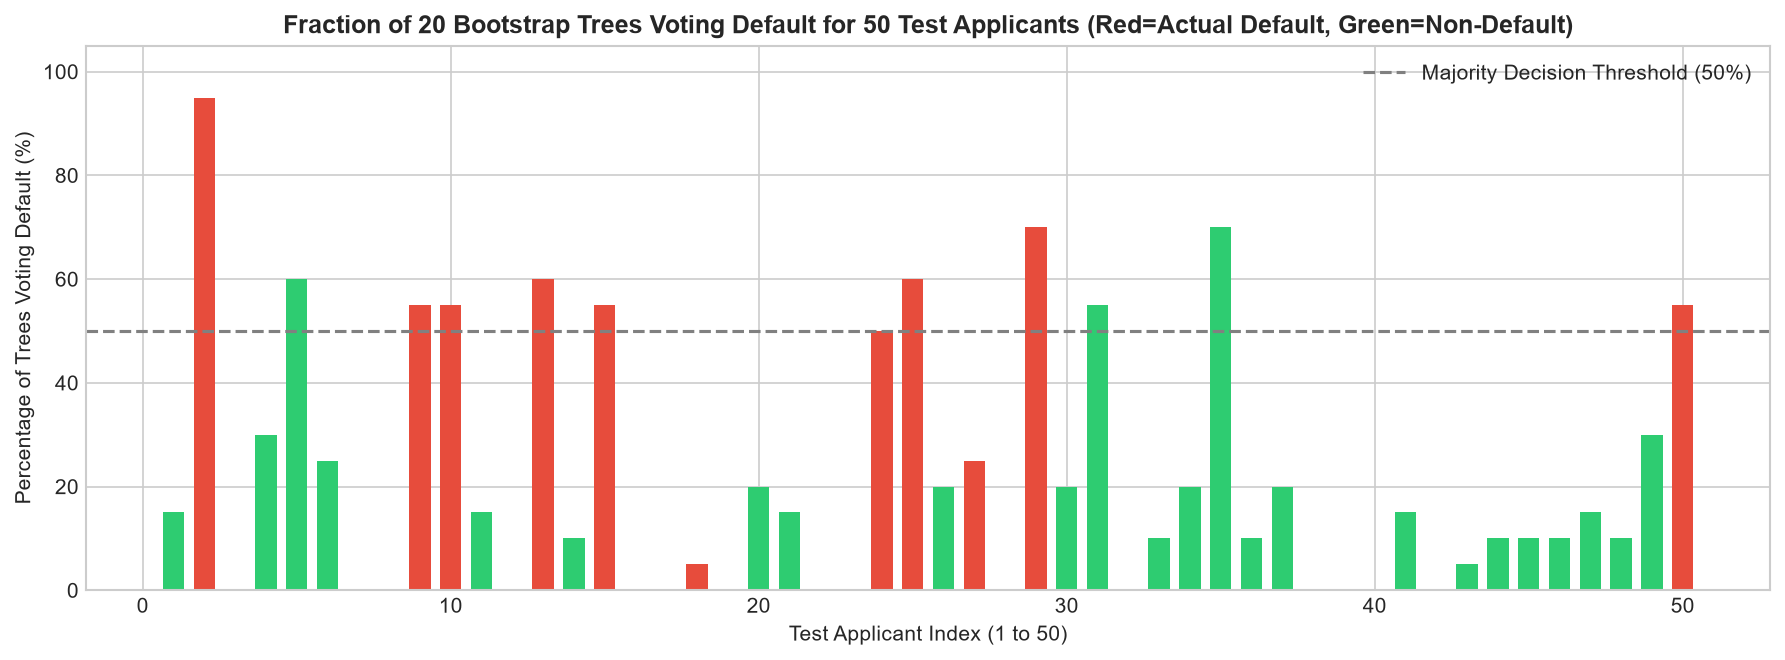

In [5]:
# Visualise Tree Prediction Disagreement across the 50 Applicants
fig, ax = plt.subplots(figsize=(12, 4.5))

vote_fractions = bootstrap_predictions.mean(axis=0) * 100
colors_votes = ['#e74c3c' if y == 1 else '#2ecc71' for y in y_test_50]

ax.bar(range(1, n_sample_test + 1), vote_fractions, color=colors_votes, width=0.7)
ax.axhline(50, color='gray', linestyle='--', label='Majority Decision Threshold (50%)')
ax.set_title('Fraction of 20 Bootstrap Trees Voting Default for 50 Test Applicants (Red=Actual Default, Green=Non-Default)', weight='bold')
ax.set_xlabel('Test Applicant Index (1 to 50)')
ax.set_ylabel('Percentage of Trees Voting Default (%)')
ax.set_ylim(0, 105)
ax.legend()

plt.tight_layout()
plt.savefig('../../outputs/figures/loan_default_tree_disagreement.png', dpi=150)
plt.show()

**Takeaway:** Disagreement across individual bootstrap trees peaks around the decision boundary, where applicant profiles have borderline creditworthiness. Averaging tree predictions smooths out individual errors and lowers overall prediction variance.

## 5. Full Random Forest Training & Out-of-Bag (OOB) Evaluation


In [6]:
# Fit Random Forest with OOB scoring enabled
rf = RandomForestClassifier(
    n_estimators=200,
    max_features='sqrt',
    min_samples_leaf=10,
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf.fit(X_train_trans, y_train)

# Predictions
y_test_pred_rf = rf.predict(X_test_trans)
y_test_prob_rf = rf.predict_proba(X_test_trans)[:, 1]

# Metrics
rf_metrics = {
    'Model': 'Random Forest Ensemble (200 trees)',
    'OOB_Score': rf.oob_score_,
    'Test_Accuracy': accuracy_score(y_test, y_test_pred_rf),
    'Test_Precision': precision_score(y_test, y_test_pred_rf),
    'Test_Recall': recall_score(y_test, y_test_pred_rf),
    'Test_F1': f1_score(y_test, y_test_pred_rf),
    'Test_ROC_AUC': roc_auc_score(y_test, y_test_prob_rf)
}

df_rf_res = pd.DataFrame([rf_metrics])
display(df_rf_res)

,Model,OOB_Score,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC
0,Random Forest Ensemble (200 trees),0.858125,0.8505,0.721461,0.39899,0.513821,0.865908


## 6. Feature Importance: MDI (Gini) vs. Permutation Importance


In [7]:
# Extract feature names
feature_names = (
    numeric_cols +
    list(preprocessor.named_transformers_['nom'].named_steps['ohe'].get_feature_names_out(nominal_cols)) +
    ordinal_cols +
    binary_cols
)

# 1. Mean Decrease in Impurity (MDI)
mdi_importances = rf.feature_importances_

# 2. Permutation Importance on Test Set
perm_res = permutation_importance(rf, X_test_trans, y_test, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_importances = perm_res.importances_mean

# Compile Comparison Table
df_fi_comp = pd.DataFrame({
    'Feature': feature_names,
    'MDI_Gini_Importance': mdi_importances,
    'Permutation_Importance': perm_importances
}).sort_values('Permutation_Importance', ascending=False).reset_index(drop=True)

df_fi_comp.to_csv('../../outputs/tables/rf_feature_importance_comparison.csv', index=False)

print('=== Top 10 Predictors: MDI vs. Permutation Importance ===')
display(df_fi_comp.head(10))

=== Top 10 Predictors: MDI vs. Permutation Importance ===


,Feature,MDI_Gini_Importance,Permutation_Importance
0,Credit_Score,0.213251,0.0277
1,Interest_Rate_Pct,0.120902,0.0099
2,Late_Payments_2Y,0.080272,0.0094
3,Ever_Delinquent,0.048024,0.0082
4,Debt_to_Income,0.058200,0.0055
5,Previous_Default,0.027958,0.0055
6,Credit_Utilization_Pct,0.057098,0.0045
7,Years_Employed,0.021772,0.0042
8,Salary_Account_With_Bank,0.007308,0.0038
9,Employment_Type_Unemployed,0.008477,0.0035


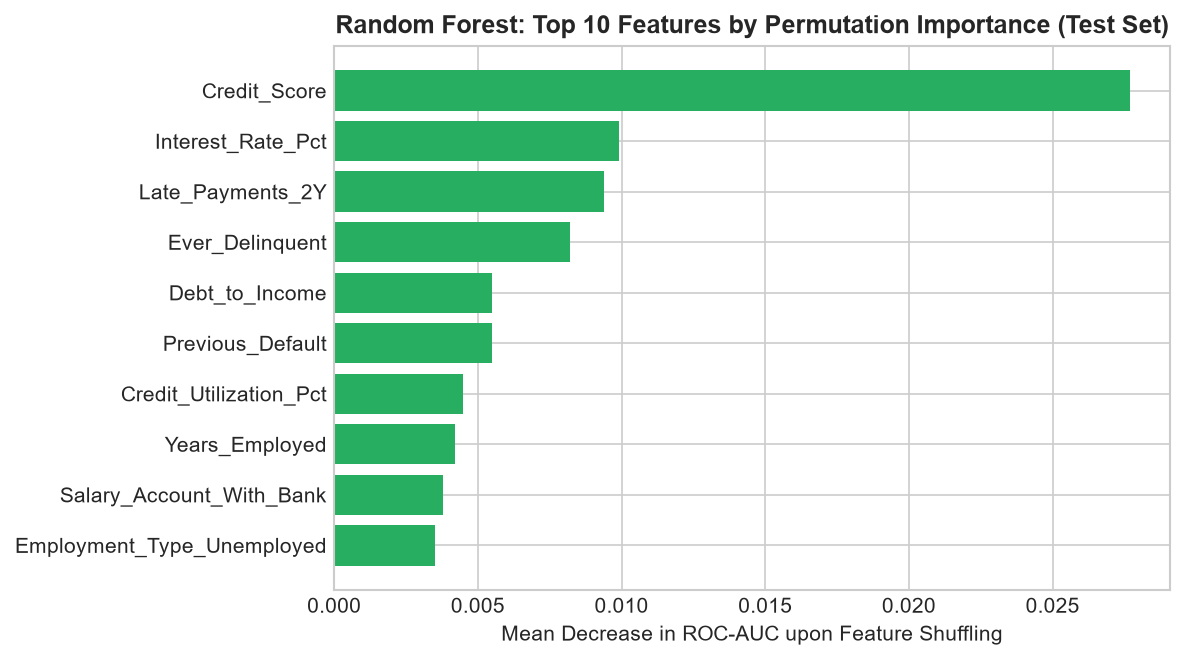

In [8]:
# Visualise Top 10 Permutation Importances
fig, ax = plt.subplots(figsize=(8, 4.5))
top_10 = df_fi_comp.head(10).sort_values('Permutation_Importance', ascending=True)
ax.barh(top_10['Feature'], top_10['Permutation_Importance'], color='#27ae60')
ax.set_title('Random Forest: Top 10 Features by Permutation Importance (Test Set)', weight='bold')
ax.set_xlabel('Mean Decrease in ROC-AUC upon Feature Shuffling')
plt.tight_layout()
plt.savefig('../../outputs/figures/loan_default_rf_permutation_importance.png', dpi=150)
plt.show()

**Takeaway:** Permutation feature importance confirms that Credit_Score, Late_Payments_2Y, DTI, and Previous_Default constitute the core quartet of default risk predictors.